# Feature Engineering Notes (Theory)

## 1. Feature Engineering
Feature Engineering is the process of transforming raw data into meaningful features that improve model performance.

It includes four main steps:
- **Feature Transformation**
- **Feature Construction**
- **Feature Selection**
- **Feature Extraction**

---

## 2. Feature Transformation

### (a) Missing Value Imputation
- Many datasets have missing values.
- Replace missing values with:
  - **Mean / Median / Mode** → keeps data balanced
  - Drop columns → if too many missing values

---

### (b) Handling Categorical Features
- ML models work with numbers, not text.
- Convert categorical features using:
  - **Label Encoding** → assigns numbers to categories
  - **One-Hot Encoding** → creates binary columns for each category

---

### (c) Outlier Detection
- Outliers = extreme values that can mislead the model.
- Detection methods:
  - **IQR (Interquartile Range)**
- Handling methods:
  - Remove them
  - Cap or transform them

---

### (d) Feature Scaling
- Some algorithms are sensitive to feature magnitude (e.g., Logistic Regression, SVM, KNN).
- Methods:
  - **Standardization** → mean = 0, std = 1
  - **Normalization** → scale values between [0,1]

---

## 3. Feature Construction
Creating new features from existing ones.

Examples:
- **Family Size** = (SibSp + Parch + 1)
- **IsAlone** = 1 if no family, else 0
- **Title extraction** from names (Mr, Mrs, Miss, etc.)

---

## 4. Feature Selection
Not all features are useful. Some may be redundant or noisy.

Techniques:
- **Statistical tests** (Chi-square, ANOVA)
- **Model-based selection** (Random Forest, XGBoost feature importance)

---

## 5. Feature Extraction
Reduce dimensionality while keeping important information.

- **PCA (Principal Component Analysis)** → converts features into fewer dimensions , LDA , TSNA
- Benefits:
  - Reduces overfitting
  - Helps visualization
  - Avoids curse of dimensionality



# 📏 Feature Scaling – Theory & Practice

Feature scaling is a **core step in feature engineering**.
It is used to **standardize the range of independent variables** (features) in a dataset.
Many ML algorithms are **sensitive to the scale of features**, especially:

- Distance-based algorithms (KNN, K-Means, SVM)
- Gradient-based optimization algorithms (Linear/Logistic Regression, Neural Networks)

Scaling ensures that **all features contribute equally** to the model.

---

## 1️⃣ Importance of Feature Scaling

1. **Distance-based algorithms**
   - Example: Euclidean distance in KNN:
     \[
     \text{distance} = \sqrt{(x_1 - y_1)^2 + (x_2 - y_2)^2 + ...}
     \]
     If features have different scales, larger magnitude features dominate the distance.

2. **Faster convergence of gradient descent**
   - Similar scale features help optimization algorithms reach minima efficiently.

3. **Better regularization**
   - Regularization techniques (L1/L2) assume features are on similar scales.

---

## 2️⃣ Feature Scaling Techniques

### 2.1 Normalization (Min-Max Scaling)

- **Goal:** Scale features to a **fixed range**, usually `[0,1]`.
- **Formula:**
\[
X_{\text{normalized}} = \frac{X - X_{\min}}{X_{\max} - X_{\min}}
\]

- **Pros:** Preserves relationships and distribution shape.
- **Cons:** Sensitive to outliers.

**Python Example:**
```python
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
````

**Explanation:**

* Subtract the **minimum value** of the feature.
* Divide by the **range (max - min)**.
* Resulting values lie between 0 and 1.

---

### 2.2 Standardization (Z-score Scaling)

* **Goal:** Center features at **mean = 0** and scale to **unit variance**.
* **Formula:**

$$
X_{\text{standardized}} = \frac{X - \mu}{\sigma}
$$

Where:

* $\mu$ = mean of the feature

* $\sigma$ = standard deviation

* **Pros:** Less sensitive to outliers than normalization.

* **Commonly used in:** SVM, Logistic Regression, PCA, Neural Networks.

**Python Example:**

```python
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
```

**Explanation:**

* Subtract **mean** ($\mu$) → center at 0
* Divide by **standard deviation** ($\sigma$) → unit variance

---

### 2.3 Other Scaling Techniques

| Technique       | Formula                                                    | When to Use            |    |                                 |
| --------------- | ---------------------------------------------------------- | ---------------------- | -- | ------------------------------- |
| Robust Scaling  | $X_{\text{robust}} = \frac{X - \text{median}}{\text{IQR}}$ | Data with **outliers** |    |                                 |
| Max Abs Scaling | (X\_{\text{maxabs}} = \frac{X}{                            | X\_{\max}              | }) | Sparse data (e.g., text/TF-IDF) |

---

## 3️⃣ Normalization vs Standardization

| Aspect   | Normalization                                                | Standardization                           |
| -------- | ------------------------------------------------------------ | ----------------------------------------- |
| Range    | \[0,1]                                                       | Mean = 0, Variance = 1                    |
| Formula  | $X_{\text{norm}} = \frac{X - X_{\min}}{X_{\max} - X_{\min}}$ | $X_{\text{std}} = \frac{X - \mu}{\sigma}$ |
| Outliers | Sensitive                                                    | Less sensitive                            |
| Use Case | Neural Networks, when range matters                          | SVM, Logistic Regression, PCA             |

---

## 4️⃣ Best Practices

* **Fit on training data, transform test data** to avoid data leakage:

```python
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)  # Do NOT fit again
```

* Choose **scaling method** based on:

  * Algorithm type
  * Data distribution
  * Presence of outliers




In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_csv(r'/home/mukul/Main/Basic_DataScience-4ML/assets/data/Social_Network_Ads.csv')
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


## 🎲 What does `random_state` do?

- `random_state` controls the **random number generator** used in functions like `train_test_split`.
- Ensures **reproducibility** of results:
  - Same `random_state` → same split every run.
  - Different (or no) `random_state` → different splits on each run.

### 🔹 Why it's useful?
- **Reproducibility** → others can reproduce your results.
- **Debugging** → consistent behavior for testing.
- **Fair comparison** → same train/test split for multiple models.

### 🔹 Example
```python
from sklearn.model_selection import train_test_split
import numpy as np

X = np.arange(10).reshape((5, 2))
y = np.array([1, 0, 1, 0, 1])

# Fixed random_state = reproducible split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42
)

print("Training Data:\n", X_train)
print("Testing Data:\n", X_test)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df.drop('Purchased', axis=1),
    df['Purchased'],
    test_size=0.3,
    random_state=0
)

X_train.shape, X_test.shape
print(y_test)


132    0
309    0
341    0
196    0
246    0
      ..
216    0
259    1
49     0
238    0
343    1
Name: Purchased, Length: 120, dtype: int64


# 📘 Standardization with `StandardScaler`

The code uses **`StandardScaler`** from scikit-learn to standardize features.
Standardization means **scaling features** so that they have:

- Mean = **0**
- Standard Deviation = **1**

This helps ML algorithms (like Logistic Regression, SVM, Neural Networks, etc.) perform better because features are on the same scale.

---

## 🔹 Code Breakdown

```python
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# 1. Fit only on training data → learn mean & std for each feature
scaler.fit(X_train)

# 2. Transform training and test data using training stats
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit the scaler to the training set to learn mean and std
scaler.fit(X_train)

# Transform train and test sets using parameters learned from train set
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# it gives me numpy array but i want dataframe so i have to convert it to data frame
print(X_train_scaled)




[[-1.1631724  -1.5849703 ]
 [ 2.17018137  0.93098672]
 [ 0.0133054   1.22017719]
 [ 0.20938504  1.07558195]
 [ 0.40546467 -0.48604654]
 [-0.28081405 -0.31253226]
 [ 0.99370357 -0.8330751 ]
 [ 0.99370357  1.8563962 ]
 [ 0.0133054   1.24909623]
 [-0.86905295  2.26126285]
 [-1.1631724  -1.5849703 ]
 [ 2.17018137 -0.80415605]
 [-1.35925203 -1.46929411]
 [ 0.40546467  2.2901819 ]
 [ 0.79762394  0.75747245]
 [-0.96709276 -0.31253226]
 [ 0.11134522  0.75747245]
 [-0.96709276  0.55503912]
 [ 0.30742485  0.06341534]
 [ 0.69958412 -1.26686079]
 [-0.47689368 -0.0233418 ]
 [-1.7514113   0.3526058 ]
 [-0.67297331  0.12125343]
 [ 0.40546467  0.29476771]
 [-0.28081405  0.06341534]
 [-0.47689368  2.2901819 ]
 [ 0.20938504  0.03449629]
 [ 1.28782302  2.20342476]
 [ 0.79762394  0.26584866]
 [-0.28081405  0.15017248]
 [ 0.0133054  -0.54388463]
 [-0.18277423  0.15017248]
 [-0.08473441  0.23692961]
 [ 0.0133054  -0.25469417]
 [ 2.17018137  1.104501  ]
 [-1.7514113   0.3526058 ]
 [ 1.87606192  0.12125343]
 

# 📘 Rounding `describe()` output

- `X_test_scaled.describe()` → shows full precision descriptive statistics (mean, std, min, max, quartiles).
- `np.round(X_test_scaled.describe(), 1)` → rounds all statistics to **1 decimal place** for easier readability.

### 🔹 Key Points
- Both outputs represent the **same data**; only the **display format differs**.
- Rounding does **not change the underlying data**, just the presentation.

### 🔹 Example
```python
X_test_scaled.describe()        # Full precision
np.round(X_test_scaled.describe(), 1)  # Rounded to 1 decimal


In [11]:
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)
X_test_scaled.describe()
np,round(X_test_scaled.describe(),1)

(<module 'numpy' from '/home/mukul/Main/Basic_DataScience-4ML/.venv/lib/python3.10/site-packages/numpy/__init__.py'>,
          Age  EstimatedSalary
 count  120.0            120.0
 mean    -0.1             -0.0
 std      1.1              1.0
 min     -1.9             -1.6
 25%     -1.0             -0.7
 50%     -0.2             -0.2
 75%      0.7              0.5
 max      2.2              2.3)

In [12]:
X_test_scaled.describe()

,Age,EstimatedSalary
count,120.000000,120.000000
mean,-0.068394,-0.006231
std,1.088712,0.952412
min,-1.947491,-1.584970
25%,-0.967093,-0.659561
50%,-0.182774,-0.153478
75%,0.724094,0.497201
max,2.170181,2.319101


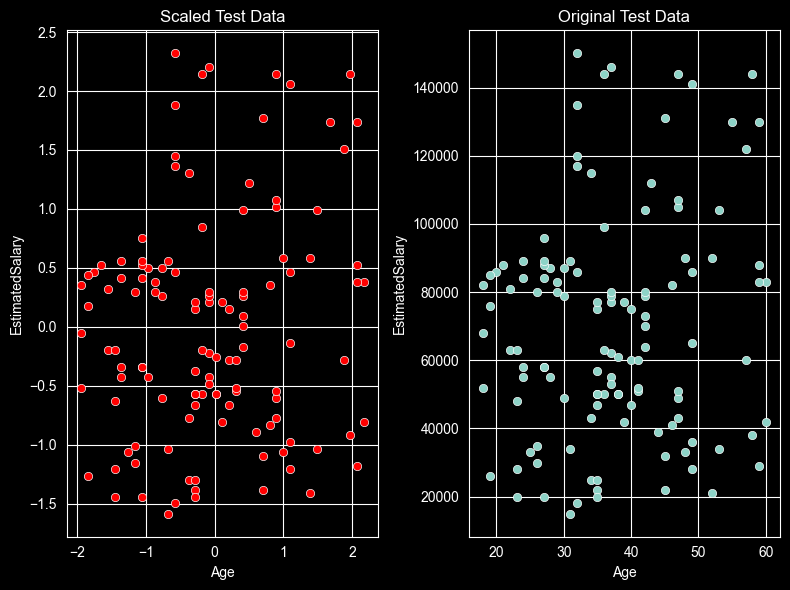

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
plt.subplot(1, 2, 1)  # 1 row, 2 columns, subplot 1
sns.scatterplot(data=X_test_scaled, x='Age', y='EstimatedSalary',color='red')
plt.title("Scaled Test Data")

plt.subplot(1, 2, 2)  # subplot 2
sns.scatterplot(data=X_test, x='Age', y='EstimatedSalary')
plt.title("Original Test Data")

plt.tight_layout()   # Adjust layout to prevent overlap
plt.show()


so here in Scalled graph the poin of 0 is in center

Text(0.5, 1.0, 'Original Test Data')

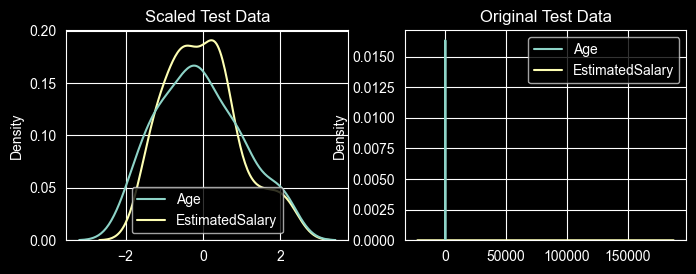

In [14]:
plt.figure(figsize=(8,6))
plt.subplot(2, 2, 1)
sns.kdeplot(data=X_test_scaled, color='red')
plt.title("Scaled Test Data")

plt.subplot(2, 2, 2)
sns.kdeplot(data=X_test, color='blue')
plt.title("Original Test Data")

# 📘 Feature Scaling & Standardization

### 🔹 Outliers and Scaling
- **Outliers** can distort some scaling methods (especially Min-Max scaling).
- Standardization (`StandardScaler`) is **less sensitive to outliers** than Min-Max, but extreme outliers can still affect mean & std.
- ✅ It's recommended to **handle or remove outliers** before scaling for better model performance.

---

### 🔹 When to use Standardization?
- Standardization **centers data to mean=0 and std=1**, making features comparable.
- Useful when algorithms rely on **distance or gradient calculations**.

---

### 🔹 Algorithms where Standardization is important
1. **K-Means** → distance-based, scales affect cluster formation.
2. **K-Nearest Neighbors (KNN)** → distance metric depends on feature scale.
3. **PCA (Principal Component Analysis)** → maximizes variance; unscaled features dominate.
4. **Artificial Neural Networks** → faster convergence, stable gradients.
5. **Gradient Descent based models** → improves learning speed and convergence.

---

✅ **Conclusion:**
- Standardization is generally **beneficial** and has **no negative impact** on most algorithms.
- Always consider handling **outliers first** for best results.
